# Use Case 3: Statistical Insights and Patterns

In this notebook I dig a bit deeper into the data:
1. how crime varies by hour of the day
2. statistics per community area with NumPy, plus outlier detection (box plot and IQR)
3. correlations between the numeric columns

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import crime_utils as cu

cu.set_style()
df = pd.read_pickle(cu.CLEAN_CRIME_FILE)
community = pd.read_pickle(cu.OUTPUT_DIR / "community_lookup.pkl")
print(f"{len(df):,} crimes loaded")

498 crimes loaded


## 1. Crime by hour of day
The `hour` column (`df['date'].dt.hour`) was added in notebook 01. `groupby('hour').size()` counts crimes in each of the 24 hours, and `reindex(range(24))` makes sure every hour is listed even if it has zero crimes.

Note: hour is unknown for all 498 crimes. The source 'date' column has dates only (e.g. 5/3/2016), so notebook 01 stored hour as NULL instead of pretending it was midnight.


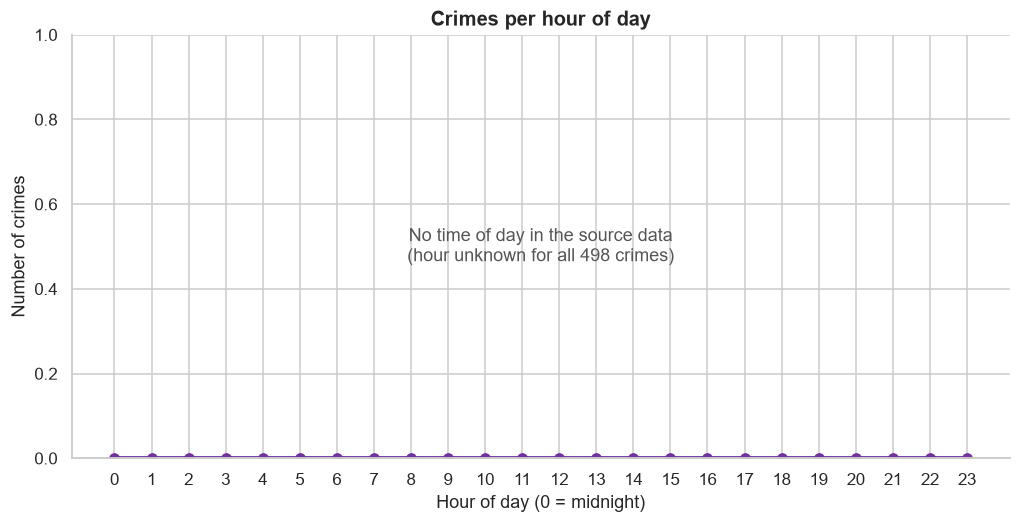

In [2]:
# hour is NULL when the source date had no time (see notebook 01), so count only known hours
known_hour = df["hour"].dropna().astype(int)
crimes_by_hour = known_hour.value_counts().reindex(range(24), fill_value=0).sort_index()
HAS_TIME = len(known_hour) > 0
if not HAS_TIME:
    print(f"Note: hour is unknown for all {len(df):,} crimes. The source 'date' column has dates only "
          "(e.g. 5/3/2016), so notebook 01 stored hour as NULL instead of pretending it was midnight.")
elif known_hour.size < len(df):
    print(f"hour is known for {known_hour.size:,} of {len(df):,} crimes; the chart uses those.")

fig, ax = plt.subplots()
ax.plot(crimes_by_hour.index, crimes_by_hour.values, marker="o", linewidth=2.5, color="#7030a0")
ax.fill_between(crimes_by_hour.index, crimes_by_hour.values, alpha=.12, color="#7030a0")
if HAS_TIME:
    peak, low = crimes_by_hour.idxmax(), crimes_by_hour.idxmin()
    ax.annotate(f"peak {peak}:00", (peak, crimes_by_hour[peak]), xytext=(0, 10),
                textcoords="offset points", ha="center", color="#c00000", fontweight="bold")
    ax.annotate(f"low {low}:00", (low, crimes_by_hour[low]), xytext=(0, -18),
                textcoords="offset points", ha="center", color="#1f4e79", fontweight="bold")
    ax.set_ylim(0, crimes_by_hour.max() * 1.15)
else:
    ax.text(0.5, 0.5, f"No time of day in the source data\n(hour unknown for all {len(df):,} crimes)",
            transform=ax.transAxes, ha="center", va="center", fontsize=12, color="#555555")
    ax.set_ylim(0, 1)
ax.set(title="Crimes per hour of day", xlabel="Hour of day (0 = midnight)", ylabel="Number of crimes")
ax.set_xticks(range(24))
cu.save_fig(fig, "uc3_01_crimes_per_hour")
plt.show()

In [3]:
if not HAS_TIME:
    print("Time-of-day bands and the per-type hourly profile are skipped: they need real times.")
    print("With timestamped data, Chicago crime typically dips around 5–6 am and rises through the "
          "afternoon and evening.")
else:
  bands = pd.cut(df["hour"], bins=[-1, 5, 11, 17, 23],
                 labels=["Night (0-5)", "Morning (6-11)", "Afternoon (12-17)", "Evening (18-23)"])
  band_share = bands.value_counts(normalize=True).mul(100).round(1).sort_index()
  display(band_share.to_frame("% of crimes").T)
  print(f"Peak hour: {peak}:00 ({crimes_by_hour[peak]:,}) | Quietest: {low}:00 ({crimes_by_hour[low]:,})")
  print(f"The peak hour has {crimes_by_hour[peak] / crimes_by_hour[low]:.1f}x the crimes of the quietest hour.")

  # Extra: does the hourly pattern change by crime type? In this heatmap each row adds up to
  # 100%, so it compares the shape of each pattern rather than the volume.
  top6 = df["primary_type"].value_counts().head(6).index
  shape = (pd.crosstab(df.loc[df["primary_type"].isin(top6), "primary_type"],
                       df.loc[df["primary_type"].isin(top6), "hour"], normalize="index") * 100)
  fig, ax = plt.subplots(figsize=(13, 4))
  sns.heatmap(shape, cmap="mako_r", ax=ax, cbar_kws={"label": "% of that crime type"})
  ax.set(title="Hourly profile of the top 6 crime types", xlabel="Hour of day", ylabel="")
  cu.save_fig(fig, "uc3_02_hourly_profile_by_type")
  plt.show()

Time-of-day bands and the per-type hourly profile are skipped: they need real times.
With timestamped data, Chicago crime typically dips around 5–6 am and rises through the afternoon and evening.


## 2. Community areas with NumPy

First I get one number for each community area: its crime count. Then I use NumPy for the summary statistics. For example, `np.mean` over the 77 counts gives the average number of crimes per community area.

In [4]:
counts = (df["community_code"].dropna().astype(int).value_counts()
            .reindex(community["community_code"].astype(int), fill_value=0))
names = community.set_index(community["community_code"].astype(int))["community_name"].str.title()

arr = counts.to_numpy()                       # plain NumPy array of 77 counts
stats = {
    "areas": arr.size,
    "mean": np.mean(arr),
    "median": np.median(arr),
    "std": np.std(arr, ddof=1),               # ddof=1 -> sample standard deviation
    "min": np.min(arr),
    "max": np.max(arr),
    "Q1 (25th pct)": np.percentile(arr, 25),
    "Q3 (75th pct)": np.percentile(arr, 75),
}
display(pd.Series(stats).round(1).to_frame("value").T)
print(f"Mean crime per community area: {stats['mean']:,.1f}")
print(f"Mean > median ({stats['mean']:.0f} > {stats['median']:.0f}) → right-skewed: "
      "a few areas have far more crime than the rest.")

,areas,mean,median,std,min,max,Q1 (25th pct),Q3 (75th pct)
value,77.0,6.5,5.0,5.9,0.0,34.0,2.0,9.0


Mean crime per community area: 6.5
Mean > median (6 > 5) → right-skewed: a few areas have far more crime than the rest.


**Per person (extra):** raw counts make big communities look worse. Dividing by population gives crimes per 1,000 residents, which is usually a fairer way to compare.

Two warnings, though. First, most areas have only a handful of crimes in this extract, so a rate can top the list on 3 crimes. Each rate gets an exact 95% interval (`cu.poisson_ci`), and I show a second ranking limited to areas with at least 10 crimes. Second, residents are the wrong denominator for places like the Loop and Near North Side, where most people present on a given day are commuters and visitors, so their per-resident rates look higher than the real risk.

In [5]:
pop = community.set_index(community["community_code"].astype(int))["population"].astype(float)
population = pop.reindex(counts.index).to_numpy()
per_1000 = arr / population * 1000
lo, hi = cu.poisson_ci(arr)                     # exact 95% interval for each count
area_stats = pd.DataFrame({"community_name": names.reindex(counts.index), "crimes": arr,
                           "population": pop.reindex(counts.index).astype("Int64"),
                           "crimes_per_1000": per_1000.round(2),
                           "ci_low": (lo / population * 1000).round(2),
                           "ci_high": (hi / population * 1000).round(2)}, index=counts.index)
city_rate = arr.sum() / np.nansum(population) * 1000

MIN_CRIMES = 10
print(f"City-wide: {city_rate:.2f} crimes per 1,000 residents")
print("Top 5 by rate, all areas (look at the crime counts and the intervals):")
display(area_stats.sort_values("crimes_per_1000", ascending=False).head(5))
print(f"Top 5 by rate, areas with at least {MIN_CRIMES} crimes:")
display(area_stats[area_stats["crimes"] >= MIN_CRIMES].sort_values("crimes_per_1000", ascending=False).head(5))

City-wide: 0.18 crimes per 1,000 residents
Top 5 by rate, all areas (look at the crime counts and the intervals):


,community_name,crimes,population,crimes_per_1000,ci_low,ci_high
community_code,,,,,,
37,Fuller Park,3,2221,1.35,0.28,3.95
26,West Garfield Park,12,15619,0.77,0.40,1.34
68,Englewood,16,21411,0.75,0.43,1.21
45,Avalon Park,7,9447,0.74,0.30,1.53
27,East Garfield Park,12,20526,0.58,0.30,1.02


Top 5 by rate, areas with at least 10 crimes:


,community_name,crimes,population,crimes_per_1000,ci_low,ci_high
community_code,,,,,,
26,West Garfield Park,12,15619,0.77,0.40,1.34
68,Englewood,16,21411,0.75,0.43,1.21
27,East Garfield Park,12,20526,0.58,0.30,1.02
67,West Englewood,13,26729,0.49,0.26,0.83
42,Woodlawn,11,23956,0.46,0.23,0.82


### Outliers: box plot and IQR

The interquartile range (IQR) is Q3 minus Q1, i.e. the spread of the middle half of the data.
A value counts as an outlier if it falls outside these limits:

* lower limit = Q1 - 1.5 x IQR
* upper limit = Q3 + 1.5 x IQR

A box plot uses the same rule to draw its whiskers and points, so the box plot shows the outliers visually and the IQR calculation gives the actual list.

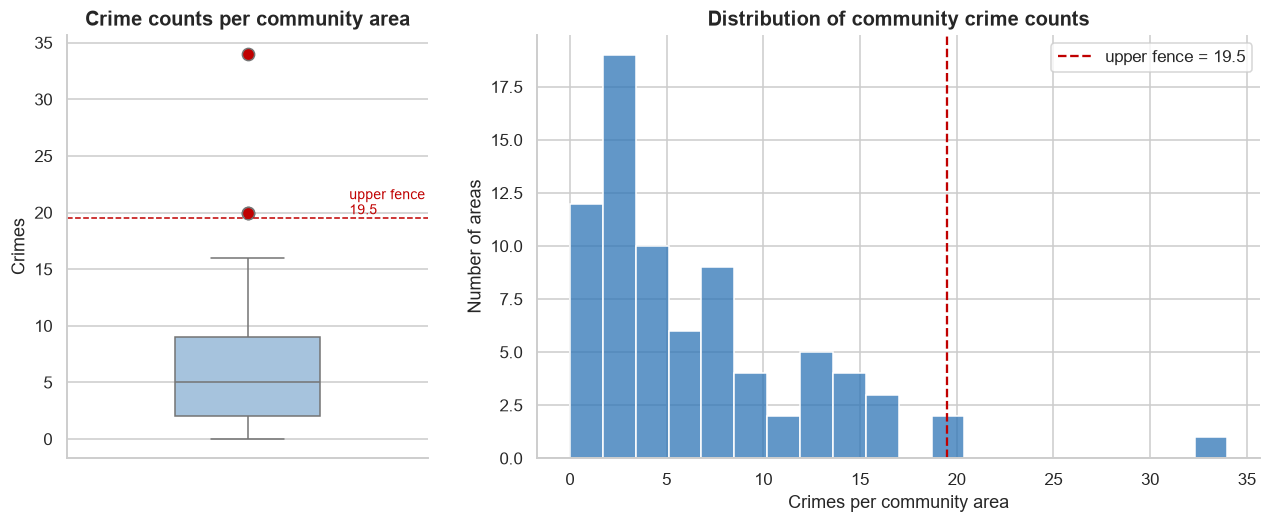

Q1 = 2.0  Q3 = 9.0  IQR = 7.0
Fences: lower = -8.5, upper = 19.5  → an area is an outlier if crimes > 19.5


In [6]:
q1, q3 = np.percentile(arr, [25, 75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 2]})
sns.boxplot(y=arr, ax=ax1, color="#9dc3e6", width=.4,
            flierprops=dict(marker="o", markerfacecolor="#c00000", markersize=8))
ax1.axhline(upper, color="#c00000", linestyle="--", linewidth=1)
ax1.text(0.27, upper, f" upper fence\n {upper:,.1f}", color="#c00000", va="bottom", fontsize=9)
ax1.set(title="Crime counts per community area", ylabel="Crimes")

sns.histplot(arr, bins=20, ax=ax2, color="#2e75b6")
ax2.axvline(upper, color="#c00000", linestyle="--", label=f"upper fence = {upper:,.1f}")
ax2.set(title="Distribution of community crime counts", xlabel="Crimes per community area",
        ylabel="Number of areas")
ax2.legend()
cu.save_fig(fig, "uc3_03_community_boxplot")
plt.show()

print(f"Q1 = {q1:,.1f}  Q3 = {q3:,.1f}  IQR = {iqr:,.1f}")
print(f"Fences: lower = {lower:,.1f}, upper = {upper:,.1f}  → an area is an outlier if crimes > {upper:,.1f}")

In [7]:
is_outlier = (arr < lower) | (arr > upper)
outliers = (area_stats[is_outlier]
              .assign(type=np.where(arr[is_outlier] > upper, "HIGH", "LOW"),
                      x_times_median=lambda d: (d["crimes"] / np.median(arr)).round(1))
              .sort_values("crimes", ascending=False))
print(f"{is_outlier.sum()} extreme outlier community area(s):")
display(outliers)

# A high count can just mean a big population. Compare each outlier with the city-wide rate.
pop_rank = area_stats["population"].rank(ascending=False, method="min")
for code, row in outliers.iterrows():
    print(f"{row['community_name']}: {row['crimes']} crimes, population rank {int(pop_rank[code])} of "
          f"{area_stats['population'].notna().sum()}, {row['crimes_per_1000']:.2f} per 1,000 residents "
          f"(city-wide {city_rate:.2f}; 95% CI {row['ci_low']:.2f}–{row['ci_high']:.2f})")
print("So these are outliers in the raw count. Whether they stand out per resident is shown by the "
      "rate and its interval, not by the box plot.")
if lower < 0:
    print("Note: the lower fence is negative, so low outliers are impossible here — "
          "only unusually HIGH-crime areas can be flagged.")

3 extreme outlier community area(s):


,community_name,crimes,population,crimes_per_1000,ci_low,ci_high,type,x_times_median
community_code,,,,,,,,
25,Austin,34,98882,0.34,0.24,0.48,HIGH,6.8
8,Near North Side,20,104712,0.19,0.12,0.29,HIGH,4.0
23,Humboldt Park,20,55598,0.36,0.22,0.56,HIGH,4.0


Austin: 34 crimes, population rank 3 of 77, 0.34 per 1,000 residents (city-wide 0.18; 95% CI 0.24–0.48)
Near North Side: 20 crimes, population rank 1 of 77, 0.19 per 1,000 residents (city-wide 0.18; 95% CI 0.12–0.29)
Humboldt Park: 20 crimes, population rank 14 of 77, 0.36 per 1,000 residents (city-wide 0.18; 95% CI 0.22–0.56)
So these are outliers in the raw count. Whether they stand out per resident is shown by the rate and its interval, not by the box plot.
Note: the lower fence is negative, so low outliers are impossible here — only unusually HIGH-crime areas can be flagged.


## 3. Correlation between columns

`.corr()` calculates the Pearson correlation (from -1 to +1) for every pair of numeric columns. I convert `arrest` and `domestic` to 0/1 so they can be included, and day of week to a number (Monday = 0). Rough guide for reading it:
* around 0: no linear relationship
* around ±0.3: weak, ±0.5: moderate, ±0.7 or more: strong

Two things to keep in mind: correlation doesn't mean one thing causes the other, and columns like `district_code`, `ward_no` and `community_code` are just ID labels, so Pearson correlation on them is meaningless. If two label columns correlate, it only tells you how the numbers were assigned across the city. The heatmap is here because the assignment asks for it; the chi-square test after it is the more useful check.

Dropped constant column(s) (correlation undefined): ['hour']


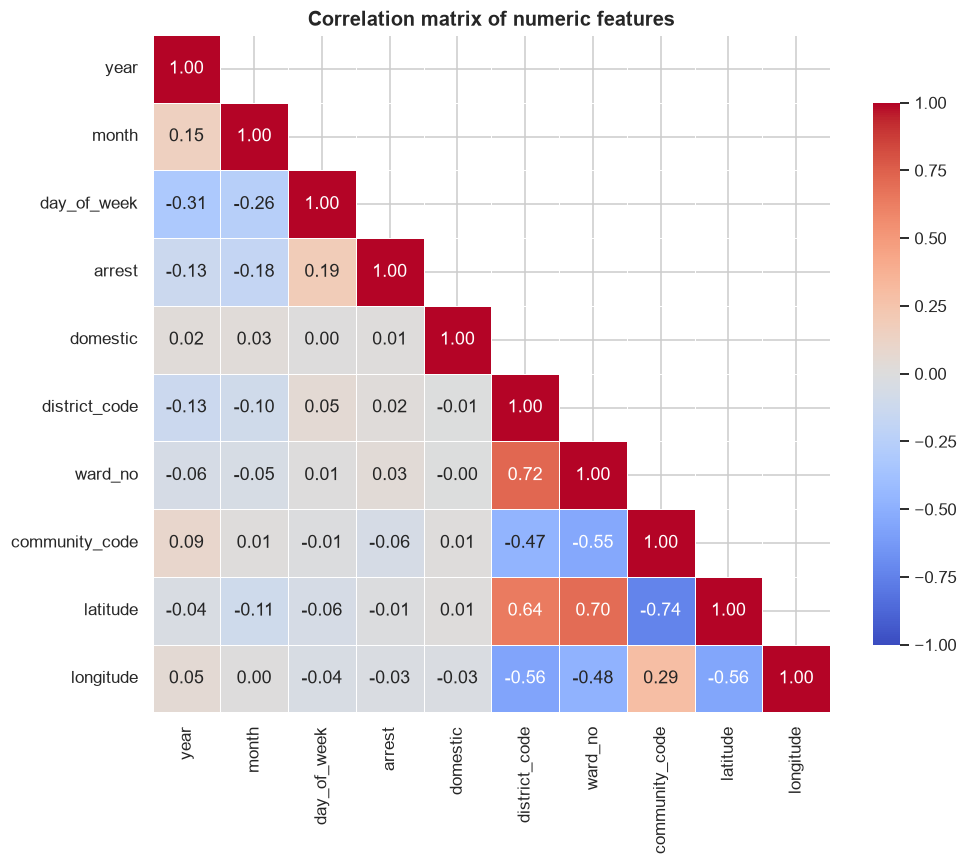

In [8]:
num = pd.DataFrame({
    "year": df["year"], "month": df["month"], "hour": df["hour"],
    "day_of_week": df["date"].dt.day_of_week,
    "arrest": df["arrest"].astype(int), "domestic": df["domestic"].astype(int),
    "district_code": df["district_code"].astype(float),
    "ward_no": df["ward_no"].astype(float),
    "community_code": df["community_code"].astype(float),
    "latitude": df["latitude"], "longitude": df["longitude"],
})
# a column with only one value (like hour = 0 everywhere) has no variance, so its correlation can't be calculated
constant = [c for c in num.columns if num[c].nunique(dropna=True) <= 1]
if constant:
    print(f"Dropped constant column(s) (correlation undefined): {constant}")
num = num.drop(columns=constant)
corr = num.corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)       # hide the duplicate upper triangle
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            center=0, linewidths=.5, square=True, ax=ax, cbar_kws={"shrink": .8})
ax.set_title("Correlation matrix of numeric features")
cu.save_fig(fig, "uc3_04_correlation_heatmap")
plt.show()

In [9]:
pairs = (corr.where(~np.tril(np.ones_like(corr, dtype=bool)))   # keep each pair once
             .stack().rename("r").reset_index()
             .rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
pairs["abs_r"] = pairs["r"].abs()
print("Strongest relationships:")
display(pairs.sort_values("abs_r", ascending=False).head(6).round(3))
r_ay = corr.loc["arrest", "year"]
strength = "none" if abs(r_ay) < 0.1 else "weak" if abs(r_ay) < 0.3 else "moderate"
n_old = (df["year"] < df["year"].max()).sum()
print(f"Arrest vs year: r = {r_ay:.3f}, which is {strength} by the guide above. It comes entirely from the "
      f"{n_old} rows dated before {df['year'].max()} (the same late-record effect as in notebook 02), "
      "so it says nothing about arrests changing over time.")
print("Note: pairs of location codes (district/ward/community/lat/long) correlate because they all "
      "describe WHERE in the city a crime happened — that's geography, not a crime insight.")
print(f"Arrest vs domestic: r = {corr.loc['arrest', 'domestic']:.3f}")

Strongest relationships:


,feature_1,feature_2,r,abs_r
78,community_code,latitude,-0.735,0.735
56,district_code,ward_no,0.721,0.721
68,ward_no,latitude,0.697,0.697
58,district_code,latitude,0.638,0.638
59,district_code,longitude,-0.564,0.564
89,latitude,longitude,-0.562,0.562


Arrest vs year: r = -0.131, which is weak by the guide above. It comes entirely from the 8 rows dated before 2016 (the same late-record effect as in notebook 02), so it says nothing about arrests changing over time.
Note: pairs of location codes (district/ward/community/lat/long) correlate because they all describe WHERE in the city a crime happened — that's geography, not a crime insight.
Arrest vs domestic: r = 0.014


### A better test for categories: chi-square and Cramér's V
Pearson correlation is meant for numbers. Most of what matters here is categorical (crime type, arrest yes/no, domestic yes/no), so a chi-square test of independence is the right tool, with Cramér's V (0 = no association, 1 = perfect) for the strength. Categories with fewer than 10 crimes are grouped into "OTHER", because chi-square is unreliable when the expected counts are tiny.

In [10]:
from scipy.stats import chi2_contingency


def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2_stat, p, dof, expected = chi2_contingency(table, correction=False)
    v = np.sqrt(chi2_stat / (table.to_numpy().sum() * (min(table.shape) - 1)))
    return v, p, (expected < 5).mean() * 100

small = df["primary_type"].map(df["primary_type"].value_counts()) < 10
crime_type = df["primary_type"].where(~small, "OTHER")
rows = []
for label, a, b in [("arrest vs crime type", df["arrest"], crime_type),
                    ("arrest vs domestic", df["arrest"], df["domestic"]),
                    ("domestic vs crime type", df["domestic"], crime_type)]:
    v, p, pct_small = cramers_v(a, b)
    rows.append({"pair": label, "cramers_v": round(v, 2), "p_value": f"{p:.1e}",
                 "% cells expected < 5": round(pct_small)})
assoc = pd.DataFrame(rows).set_index("pair")
display(assoc)
v_ad = assoc.loc["arrest vs domestic", "cramers_v"]
print(f"Crime type is strongly tied to whether there's an arrest (V = {assoc.loc['arrest vs crime type', 'cramers_v']}), "
      "which matches the arrest-rate chart in notebook 02.")
print(f"Arrest vs domestic: V = {v_ad}, p = {assoc.loc['arrest vs domestic', 'p_value']}, "
      + ("so there's no sign of a link." if v_ad < 0.1 else "a weak link." if v_ad < 0.3 else "a clear link."))

,cramers_v,p_value,% cells expected < 5
pair,,,
arrest vs crime type,0.60,3.4e-32,12
arrest vs domestic,0.01,7.5e-01,0
domestic vs crime type,0.58,6.3e-30,25


Crime type is strongly tied to whether there's an arrest (V = 0.6), which matches the arrest-rate chart in notebook 02.
Arrest vs domestic: V = 0.01, p = 7.5e-01, so there's no sign of a link.
